## Scrape BLS data without using an API

In [63]:
url= "https://data.bls.gov/timeseries/CES0000000001"

base_url="https://data.bls.gov/timeseries/"
series_id="CES0000000001"
request_parameters = f"?years_option=specific_years&from_year=2021&delimiter=comma&output_type=column&periods_option=all_periods&output_view=net_1mth&output_format=html&include_graphs=False"

full_url=base_url+series_id+request_parameters
full_url

'https://data.bls.gov/timeseries/CES0000000001?years_option=specific_years&from_year=2021&delimiter=comma&output_type=column&periods_option=all_periods&output_view=net_1mth&output_format=html&include_graphs=False'

In [64]:
import requests
from bs4 import BeautifulSoup

response = requests.get(full_url)
doc = BeautifulSoup(response.text, 'html.parser')
response.raise_for_status()

In [65]:

 # get to the rows
table = doc.find("table", {"id": "table0"})

if not table:
	print(f"No table found for {series_id}")

In [66]:

tbody = table.find("tbody")
if not tbody:
	print(f"No rows found for {series_id}")

In [67]:
trs=tbody.find_all("tr")

In [68]:
rows=[]
for tr in trs:
    cells = tr.find_all(["th", "td"], recursive=False)

    raw_value = cells[3].get_text(strip=True)
    is_preliminary = raw_value.endswith("(P)")
    clean_value = raw_value.replace("(P)", "").replace(",", "").strip()
    
    rows.append({
        "series_id": cells[0].get_text(strip=True),
        "year": int(cells[1].get_text(strip=True)),
        "period": cells[2].get_text(strip=True),
        "jobs_added": int(clean_value),
        "is_prelim": is_preliminary,
    })
import pandas as pd
df=pd.DataFrame(rows)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   series_id   69 non-null     str  
 1   year        69 non-null     int64
 2   period      69 non-null     str  
 3   jobs_added  69 non-null     int64
 4   is_prelim   69 non-null     bool 
dtypes: bool(1), int64(2), str(2)
memory usage: 2.4 KB


In [69]:
df['month']=df['year'].astype(str)+"-"+df['period'].str.replace("M", "")
df['time_stamp']=pd.to_datetime(df['month'])


df=df.drop_duplicates()

In [70]:

rows = []
for tr in tbody.find_all("tr"):
    cells = tr.find_all(["th", "td"])
    if len(cells) != 4:
        continue

    raw_value = cells[3].get_text(strip=True)
    is_preliminary = raw_value.endswith("(P)")
    clean_value = raw_value.replace("(P)", "").replace(",", "").strip()

    rows.append({
        "series_id": cells[0].get_text(strip=True),
        "year": int(cells[1].get_text(strip=True)),
        "period": cells[2].get_text(strip=True),
        "jobs_added": int(clean_value),
        "is_prelim": is_preliminary,
    })

import pandas as pd
df = pd.DataFrame(rows)
# df=clean_cols(df)
df['month']=df['year'].astype(str)+"-"+df['period'].str.replace("M", "")
df['time_stamp']=pd.to_datetime(df['month'])

df=df.drop_duplicates()

<Axes: xlabel='time_stamp'>

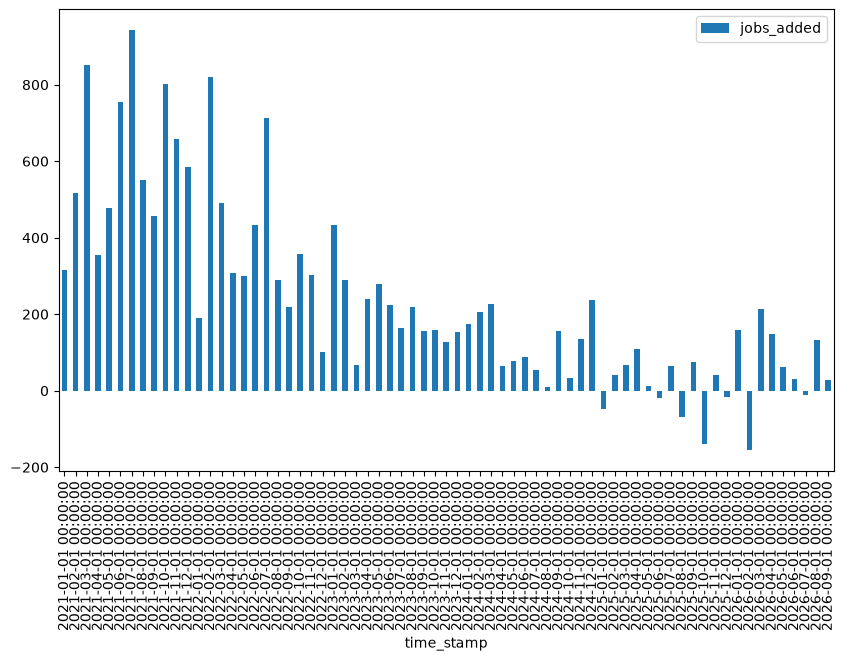

In [71]:
import matplotlib.pyplot as plt

df.plot(x='time_stamp', y='jobs_added', kind='bar', figsize=(10, 6))

In [72]:
import numpy as np

conditions = [
    df["time_stamp"] <= "2025-01-01",
    df["time_stamp"] > "2025-01-01",
]

choices =['biden', 'trump_second']

df["president"] = np.select(conditions, choices, default='unknown')

df.president.value_counts()


president
biden           49
trump_second    20
Name: count, dtype: int64

In [73]:
## lambda function:

df['lambda_prez']= df['time_stamp'].apply(lambda x: 'biden' if x <= pd.to_datetime('2025-01-01') else 'trump_second')


## a regular function

def get_president(time_stamp):
    if time_stamp <= pd.to_datetime('2025-01-01'):
        return 'biden'
    else:
        return 'trump_second'

df['regular_prez'] = df['time_stamp'].apply(get_president)



In [74]:

## pd.cut 

bins = [pd.to_datetime('2020-01-01'), pd.to_datetime('2025-02-01'), pd.to_datetime('2030-01-01')]
labels=['biden', 'trump_second']

df['pd_cut_prez'] = pd.cut(df['time_stamp'], bins=bins, labels=labels, right=False)

In [75]:
df[[ 'president', 'lambda_prez', 'regular_prez', 'pd_cut_prez']].value_counts()

president     lambda_prez   regular_prez  pd_cut_prez 
biden         biden         biden         biden           49
trump_second  trump_second  trump_second  trump_second    20
biden         biden         biden         trump_second     0
trump_second  trump_second  trump_second  biden            0
Name: count, dtype: int64

In [76]:
df['added_or_lost']=df.jobs_added.apply(lambda x: 'added' if x > 0 else 'lost')

In [77]:
df.head()

,series_id,year,period,jobs_added,is_prelim,month,time_stamp,president,lambda_prez,regular_prez,pd_cut_prez,added_or_lost
0,CES0000000001,2021,M01,315,False,2021-01,2021-01-01,biden,biden,biden,biden,added
1,CES0000000001,2021,M02,517,False,2021-02,2021-02-01,biden,biden,biden,biden,added
2,CES0000000001,2021,M03,852,False,2021-03,2021-03-01,biden,biden,biden,biden,added
3,CES0000000001,2021,M04,355,False,2021-04,2021-04-01,biden,biden,biden,biden,added
4,CES0000000001,2021,M05,478,False,2021-05,2021-05-01,biden,biden,biden,biden,added


### Inflation data

In [78]:
# API: https://data.bls.gov/timeseries/CUUR0000SA0?years_option=specific_years&to_year=2025&from_year=2015&delimiter=comma&output_type=column&periods_option=all_periods&output_view=pct_12mths&output_format=html&original_include_graphs=False&original_output_view=pct_12mths&include_graphs=False

base_url="https://data.bls.gov/timeseries/"
series_id="CUUR0000SA0"

prefix='CUUR0000'

period_option=['pct_12mths', 'pct_1mth', 'date']


major_items_dictionary={
	"All items":"SA0",
	"Food": "SAF1",
	# "Energy":"SA0E",
	# "Electricity":"SEHF01",
	# "Gasoline":"SETB01",
	# "Apparel":"SAA",
	# "New Vehicles":"SETA01",
	# "Used cars and trucks": "SETA02",
	# 'Shelter':"SAH1",
    # "Food at home": "SAF11",
	# "Food away from home": "SEFV"
}


full_url= base_url + series_id + request_parameters

full_url

'https://data.bls.gov/timeseries/CUUR0000SA0?years_option=specific_years&from_year=2021&delimiter=comma&output_type=column&periods_option=all_periods&output_view=net_1mth&output_format=html&include_graphs=False'

In [79]:
base_url="https://data.bls.gov/timeseries/"
request_parameters = f"?years_option=specific_years&from_year=2019&delimiter=comma&output_type=column&periods_option=all_periods&output_format=html&include_graphs=False"

def fetch_bls_data(series_id):

    url= base_url+prefix+series_id+request_parameters
    response = requests.get(url)
    response.raise_for_status()
    doc = BeautifulSoup(response.text, 'html.parser')

     # get to the rows
    table = doc.find("table", {"id": "table0"})
    if not table:
        print(f"No table found for {series_id}")

    tbody = table.find("tbody")
    if not tbody:
        print(f"No rows found for {series_id}")
    

    data = []

    for row in tbody.find_all("tr"):
        cells = row.find_all(["th","td"])
        cells = [cell.get_text(strip=True) for cell in cells]
        if cells:
            data.append(cells)

    df = pd.DataFrame(data, columns=["series_id", "year", "month", "value"])

    return df

In [80]:
dfs=[]

for category, series_id in major_items_dictionary.items():
    df = fetch_bls_data(series_id)
    df['category'] = category
    print(df.shape)
    dfs.append(df)
    # Do something with the fetched data, e.g., save it to a file or upload it

master_df = pd.concat(dfs, ignore_index=True)

(108, 5)
(108, 5)


In [81]:
    # Clean up
remove_months = ['S01', 'S02', 'M13']
master_df = master_df[~master_df.month.isin(remove_months)].reset_index(drop=True)
# master_df = master_df[master_df['value']!="(X)"].reset_index(drop=True)
# master_df = master_df[master_df['value']!="-(X)"].reset_index(drop=True)
master_df['value'] = master_df['value'].replace({"(X)": np.nan, "-(X)": np.nan})
master_df["date"] = master_df.year + "-" + master_df.month.str.replace("M", "")
master_df["value"] = master_df["value"].astype(float)

In [82]:
pvtd_df=master_df.pivot(index='date', columns='category', values='value').reset_index()

In [83]:
pvtd_df.head()

category,date,All items,Food
0,2019-01,251.712,256.417
1,2019-02,252.776,257.222
2,2019-03,254.202,257.724
3,2019-04,255.548,257.708
4,2019-05,256.092,258.110


<Axes: xlabel='date'>

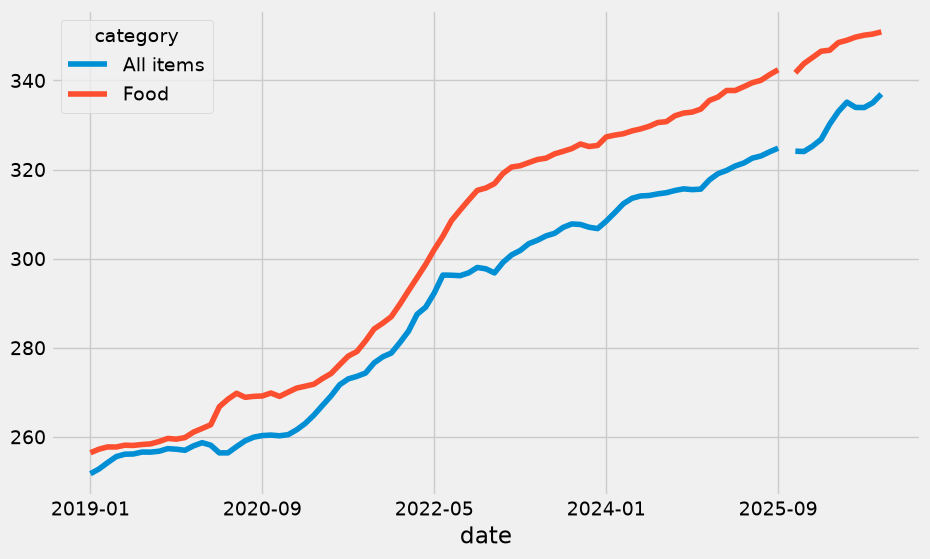

In [84]:
plt.style.use('fivethirtyeight')

pvtd_df.plot(x='date', y=['All items', 'Food'], kind='line', figsize=(10, 6))